<img src="https://raw.githubusercontent.com/riazcseiu/fmlds2026-multimodal-workshop/main/assets/banner.png" width="100%">

# Notebook 3 · Video → People → Stops
**The vision modality**  ·  ⏱ about 15 minutes

### What you will learn
- Run **YOLOv11** person detection and **DeepSORT** tracking live on event footage
- Turn trajectories into **stop events** (≥ 5 s inside a small radius) and **dwell times**
- Visualise where visitors walk and linger — trajectories and heatmaps
- Understand the practical issues: ID switches, occlusion, staff, camera coverage

> **The story so far.** At the *Imagine Coffee Event* — a two-hour Sunday-morning pop-up market in Matsue, Japan — we asked visitors what they noticed (**interviews → language**) and we filmed what they actually did (**video → vision**).
> This workshop combines both modalities to answer one question: *do people do what they say?*

<small>Data: a reduced, anonymised teaching subset derived from Mian & Nguyen-Tran (World 2026) and Nguyen-Tran, Majiid & Mian (World 2025). Names removed, participants sub-sampled, ~10% of utterances dropped. Do not use for research claims.</small>


> **Runtime tip.** For the live-tracking part choose **Runtime → Change runtime type → T4 GPU**. Without a GPU it still works, just slower (we process only a few seconds).
> **Privacy.** All footage in this repository is face-blurred, and the foreground corner is masked. Trajectory files contain only an anonymous ID and a position.

In [1]:
# ▶ Run this cell first — it fetches the workshop data (about 20 s in Colab)
import os, sys, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/riazcseiu/fmlds2026-multimodal-workshop'
if IN_COLAB:
    if not os.path.exists('fmlds2026-multimodal-workshop'):
        os.system(f'git clone -q --depth 1 {REPO_URL}')
    BASE = 'fmlds2026-multimodal-workshop'
else:
    BASE = '..'          # running locally from the notebooks/ folder
DATA = os.path.join(BASE, 'data')
RESULTS = os.path.join(BASE, 'data', 'results'); os.makedirs(RESULTS, exist_ok=True)

import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
COL = {'onsite': '#2A9D8F', 'video': '#4361EE', 'virtual': '#9B5DE5', 'P': '#4361EE', 'B': '#D9731A'}
print('Data folder:', os.path.abspath(DATA))

In [ ]:
from IPython.display import Video, display
VIDEO = f'{DATA}/video/imagine_coffee_clip05_tracked_blurred.mp4'
display(Video(VIDEO, embed=True, width=720))

This is the output of our full pipeline on one clip: each box is a person, the number is their tracking **ID**, which stays the same as they move. Below we rebuild that pipeline step by step.

## 1 · Live: detect and track (≈ 1–3 min)
**YOLOv11** looks at each frame independently and draws boxes around people.
**DeepSORT** links boxes across frames into tracks, using motion (Kalman filter) *and* appearance (a small re-identification CNN), so a person keeps one ID even after brief occlusion.

*(The demo clip already has boxes drawn on it from our earlier run — YOLO still finds the people underneath.)*

In [ ]:
import subprocess, importlib
for pkg, mod in [('ultralytics', 'ultralytics'), ('deep-sort-realtime', 'deep_sort_realtime')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run(['pip', '-q', 'install', pkg])
import cv2, torch
from ultralytics import YOLO
from deep_sort_realtime.deepsort_tracker import DeepSort
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('device:', 'GPU' if DEVICE == 0 else 'CPU')

In [4]:
SECONDS = 4                 # how much video to process live — increase if you have a GPU
model = YOLO('yolo11n.pt')   # 'n' = nano, the smallest/fastest model
tracker = DeepSort(max_age=30, n_init=3, embedder='mobilenet', embedder_gpu=(DEVICE == 0))

cap = cv2.VideoCapture(VIDEO); fps = cap.get(cv2.CAP_PROP_FPS)
W, H = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter(f'{RESULTS}/live_tracking_raw.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
live_rows = []
for f in range(int(SECONDS * fps)):
    ok, frame = cap.read()
    if not ok: break
    det = model(frame, classes=[0], conf=0.35, imgsz=640, device=DEVICE, verbose=False)[0]
    dets = [([x1, y1, x2 - x1, y2 - y1], float(c), 'person')
            for (x1, y1, x2, y2), c in zip(det.boxes.xyxy.cpu().numpy(), det.boxes.conf.cpu().numpy())]
    for t in tracker.update_tracks(dets, frame=frame):
        if not t.is_confirmed(): continue
        x1, y1, x2, y2 = map(int, t.to_ltrb())
        live_rows.append(dict(frame=f, time_s=f / fps, track_id=t.track_id, foot_x=(x1 + x2) / 2, foot_y=y2))
        cv2.rectangle(frame, (x1, y1), (x2, y2), (26, 115, 217), 3)
        cv2.putText(frame, f'ID {t.track_id}', (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, .6, (26, 115, 217), 2)
    out.write(frame)
cap.release(); out.release()
live = pd.DataFrame(live_rows)
print(f'{f + 1} frames processed · {live.track_id.nunique()} confirmed tracks')

120 frames processed · 13 confirmed tracks


In [ ]:
# convert to a browser-friendly format and play
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', f'{RESULTS}/live_tracking_raw.mp4',
                '-c:v', 'libx264', '-preset', 'veryfast', '-pix_fmt', 'yuv420p', f'{RESULTS}/live_tracking.mp4'])
display(Video(f'{RESULTS}/live_tracking.mp4', embed=True, width=720))

**Look closely:** do any IDs jump to a different person, or does one person get two IDs? That is an **ID switch**. In our study a small human-assisted interface let analysts merge or reassign IDs and remove stall staff before analysis.

## 2 · Full-clip trajectories (pre-computed)
Tracking 90 s of video takes a while, so we load the trajectories we already computed for three clips.
Each row: `frame, time_s, track_id, box (x1,y1,x2,y2), foot_x, foot_y`. The **foot point** (bottom-centre of the box) is where the person stands on the ground.

In [6]:
tracks = {c: pd.read_csv(f'{DATA}/tracking/tracks_{c}.csv') for c in ['clip02', 'clip05', 'clip08']}
summary = pd.read_csv(f'{DATA}/tracking/summary.csv')
display(summary)
tracks['clip05'].head()

,video,seconds_processed,unique_tracks,avg_people_per_frame,tracks_>=2s,stops,mean_dwell_s,max_dwell_s,processing_fps
0,clip02,89.6,103,6.75,49,31,15.6,51.8,0.8
1,clip05,89.6,121,9.32,64,57,12.9,46.7,2.4
2,clip08,89.6,100,7.47,50,48,12.0,43.0,2.5


,frame,time_s,track_id,x1,y1,x2,y2,foot_x,foot_y
0,2,0.066667,1,919.488502,492.119398,1163.299573,719.240787,1041.394038,719.240787
1,2,0.066667,2,1085.435717,524.633615,1233.812282,716.288420,1159.624000,716.288420
2,2,0.066667,3,431.998333,343.970140,493.208365,579.548656,462.603349,579.548656
3,2,0.066667,4,218.493021,336.321633,290.670701,601.783271,254.581861,601.783271
4,2,0.066667,5,363.134747,390.807173,419.804311,545.447714,391.469529,545.447714


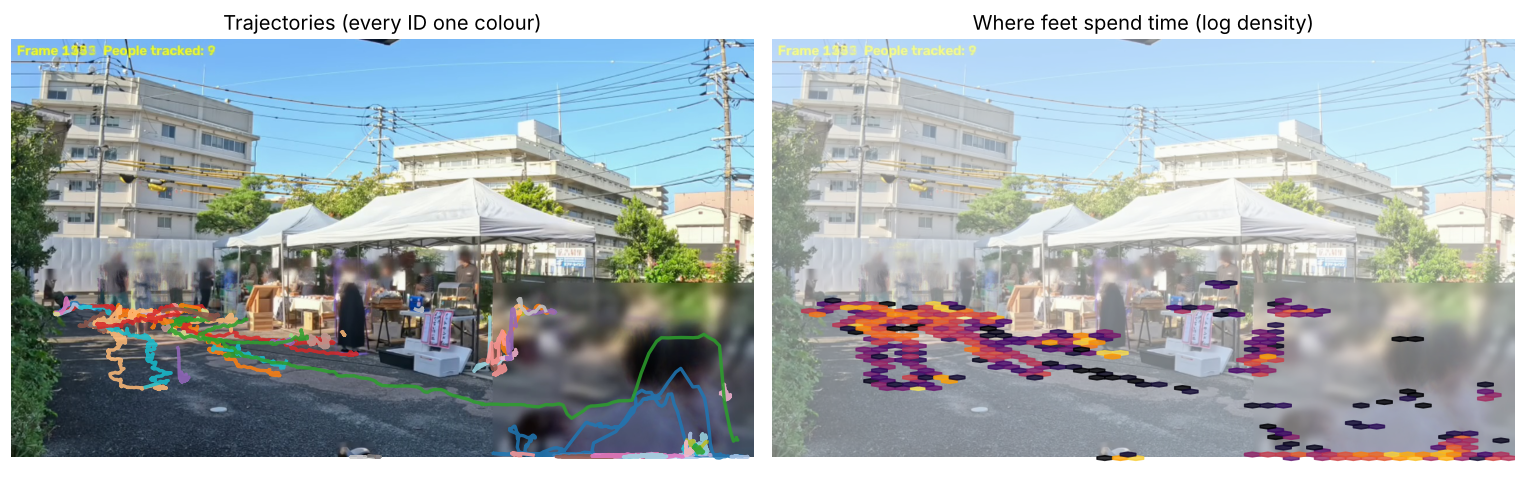

In [7]:
bg = plt.imread(f'{DATA}/video/scene_background.jpg')
t = tracks['clip05']
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
axs[0].imshow(bg); axs[0].set_title('Trajectories (every ID one colour)')
for i, (tid, g) in enumerate(t.groupby('track_id')):
    if len(g) > 30: axs[0].plot(g.foot_x, g.foot_y, lw=2.2, alpha=.85, color=plt.cm.tab20(i % 20))
axs[1].imshow(bg, alpha=.55)
h = axs[1].hexbin(t.foot_x, t.foot_y, gridsize=45, mincnt=3, cmap='inferno', alpha=.8, bins='log')
axs[1].set_title('Where feet spend time (log density)')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
display(Video(f'{DATA}/video/imagine_coffee_clip05_trajectories.mp4', embed=True, width=720))

## 3 · From trajectories to **stop events**
A visitor *stops* when they stay within a small radius **R** for at least **T = 5 s**. We implement it from scratch:
1. Walk along each track.
2. Keep an *anchor* point; while the person stays within R pixels of it, extend the stop.
3. If the stay lasts ≥ T seconds, record a stop with its duration (**dwell time**).

In [9]:
R_PX, T_MIN = 45, 5.0

def detect_stops(track_df, r=R_PX, tmin=T_MIN):
    stops = []
    for tid, g in track_df.sort_values('time_s').groupby('track_id'):
        xy, ts = g[['foot_x', 'foot_y']].to_numpy(), g.time_s.to_numpy()
        i = 0
        while i < len(g):
            j = i
            while j + 1 < len(g) and np.hypot(*(xy[j + 1] - xy[i])) <= r:
                j += 1
            if ts[j] - ts[i] >= tmin:
                stops.append(dict(track_id=tid, start_s=ts[i], end_s=ts[j], dwell_s=ts[j] - ts[i],
                                  x=xy[i:j + 1, 0].mean(), y=xy[i:j + 1, 1].mean()))
                i = j + 1
            else:
                i += 1
    return pd.DataFrame(stops)

stops = {c: detect_stops(t) for c, t in tracks.items()}
pd.DataFrame({c: dict(stops=len(s), mean_dwell_s=s.dwell_s.mean().round(1), max_dwell_s=s.dwell_s.max().round(1))
              for c, s in stops.items()}).T

,stops,mean_dwell_s,max_dwell_s
clip02,29.0,15.9,51.8
clip05,56.0,12.3,46.5
clip08,45.0,11.9,42.7


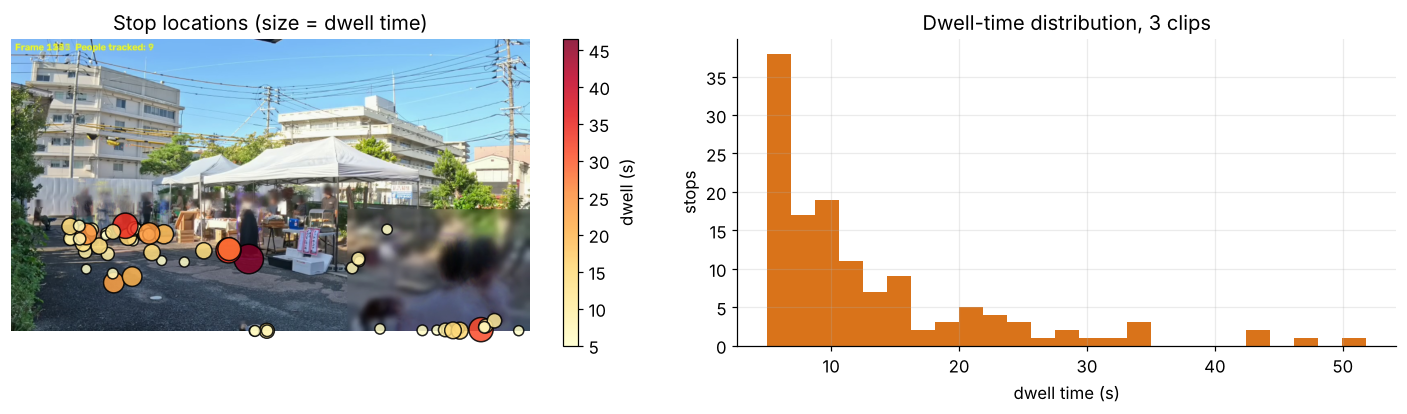

In [10]:
s = stops['clip05']
fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
axs[0].imshow(bg); sc = axs[0].scatter(s.x, s.y, s=s.dwell_s * 8, c=s.dwell_s, cmap='YlOrRd', edgecolor='k', alpha=.85)
axs[0].set_title('Stop locations (size = dwell time)'); axs[0].axis('off'); plt.colorbar(sc, ax=axs[0], label='dwell (s)')
allst = pd.concat([v.assign(clip=k) for k, v in stops.items()])
axs[1].hist(allst.dwell_s, bins=25, color=COL['B']); axs[1].set_xlabel('dwell time (s)'); axs[1].set_ylabel('stops')
axs[1].set_title('Dwell-time distribution, 3 clips')
plt.tight_layout(); plt.show()

In [11]:
# The paper aggregates visitors at several dwell thresholds
thr = pd.DataFrame({f'>{k}s': [int((v.dwell_s > k).sum()) for v in stops.values()] for k in [5, 10, 15, 20]},
                   index=list(stops.keys()))
thr

,>5s,>10s,>15s,>20s
clip02,29,14,12,8
clip05,55,24,12,9
clip08,45,20,11,7


### From stops to a **behavioural score per stall**
In the full study each stop was assigned to the nearest stall / advertisement region, counts were corrected for **camera coverage** ($V_w = V_{obs}/c$ — a stall visible in fewer clips must not be penalised) and normalised to a 0–5 behavioural score **B**. Those stall-level scores are what Notebook 4 fuses with the interviews.

In [12]:
allst.to_csv(f'{RESULTS}/nb3_stops_all_clips.csv', index=False)

## ✏️ Try it yourself (3 min)
1. Change `R_PX` to 25 and 80. How sensitive is the number of stops?
2. Change `T_MIN` to 10 s. Which clip loses the most stops?
3. In the live tracking, try `conf=0.2` — more people found, but more false boxes?

**Next →** `04_fusion_gap.ipynb` — put **said** and **did** side by side.